<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_1_Yield_Prediction/Machine_Learning_Pipeline/Preprocessing_and_ModelTraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Google Drive to get the final dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [23]:
import pandas as pd
import numpy as np

final_data_path = '/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Merged.csv'

# Load final data
final_data = pd.read_csv(final_data_path)
df = final_data.copy()

In [9]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.2 MB/s eta 0:00:00


In [10]:
# GENERAL PURPOSE LIBRARIES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# SKLEARN TOOLS
from sklearn.linear_model import Lasso, Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# XGBOOST
from xgboost import XGBRegressor

# CATBOOST
from catboost import CatBoostRegressor

## **Data Preprocessing**

### Remove Missing Rows

In [24]:
# Keep rows where YPH is not missing
df = df[df['YPH'].notna()]

### Data Type Conversion

In [25]:
month_map = {
    'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
    'July':7,'August':8,'September':9,'October':10,'November':11,'December':12
}
df['Month'] = df['Month'].map(month_map)

### Remove irrelevant columns

In [26]:
df = df.drop(columns=['Month'])

In [27]:
# Remove highly correlated features
df = df.drop(columns=['temperature_2m_min',
                      'temperature_2m_max',
                      'relative_humidity_2m_min',
                      'relative_humidity_2m_max',
                      'wind_speed_10m_max',
                      'precipitation_sum'])

# Display remaining columns to verify
print("Remaining columns after dropping redundant weather features:")
print(df.columns)

Remaining columns after dropping redundant weather features:
Index(['Year', 'YPH', 'T200', 'UT925', 'U709', 'Epson Salt', 'Dolomite',
       'Urea', 'Zinc', 'Compost', 'BioShakthi', 'BioShield',
       'temperature_2m_mean', 'relative_humidity_2m_mean', 'rain_sum',
       'sunshine_duration', 'wind_speed_10m_mean',
       'et0_fao_evapotranspiration'],
      dtype='object')


# **CatBoost**

### Model Based Preprocessing

In [28]:
# Create copy
df_catboost = df.copy()

# Feature Engineering
df_catboost['Year_trend'] = df_catboost['Year'] - df_catboost['Year'].min()

# YPH lags
for lag in [1, 6, 12]:
    df_catboost[f'YPH_lag{lag}'] = df_catboost['YPH'].shift(lag).bfill()

# Fertilizer lags
for fert in ['UT925', 'U709', 'Dolomite']:
    df_catboost[f'{fert}_lag1'] = df_catboost[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_catboost.columns if col not in ['YPH', 'Year']]

# Walk Forward Validation test years
all_years = sorted(df_catboost['Year'].unique())
test_years = [y for y in all_years if all(ty in all_years for ty in [y-3, y-2, y-1])]

# Data Augmentation
def add_gaussian_noise(X, y, noise_std=0.03, n_augmentations=2):
    """Add Gaussian noise to augment training data"""
    X_aug = [X.values.copy()]
    y_aug = [y.values.copy()]

    for _ in range(n_augmentations):
        noise = np.random.normal(0, noise_std * X.std(), X.shape)

        # Reduce noise for lag features
        lag_cols = [col for col in X.columns if 'YPH_lag' in col]
        for col in lag_cols:
            noise[:, X.columns.get_loc(col)] *= 0.7

        X_aug.append(X.values + noise)
        y_noise = np.random.normal(0, noise_std * 0.5 * y.std(), y.shape)
        y_aug.append(y.values + y_noise)

    return np.vstack(X_aug), np.hstack(y_aug)

### Model Training

In [29]:
train_results = []
test_results = []

for test_year in test_years:

    train_years = [test_year - 3, test_year - 2, test_year - 1]

    train_df = df_catboost[df_catboost['Year'].isin(train_years)]
    test_df  = df_catboost[df_catboost['Year'] == test_year]

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    # Augment training data
    X_train_aug, y_train_aug = add_gaussian_noise(X_train, y_train)

    # Model
    model = CatBoostRegressor(
        iterations=300,
        depth=3,
        learning_rate=0.025,
        l2_leaf_reg=15,
        min_data_in_leaf=25,
        subsample=0.7,
        random_strength=1.0,
        loss_function='RMSE',
        random_seed=42,
        verbose=False
    )

    # Training
    model.fit(X_train_aug, y_train_aug)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    # Store metrics for evaluation
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'train_years': train_years,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.736065  2.849938  13.958181  0.975852
1  2021  2.827945  2.005280   7.997270  0.986503
2  2022  2.502934  1.754941   6.264679  0.990252
3  2023  2.582463  1.894106   6.669116  0.990196
4  2024  2.706145  1.904223   7.323223  0.989275
5  2025  2.594206  1.899387   6.729907  0.990180

TEST METRICS PER YEAR
   year         train_years       rmse        mae         mse        r2
0  2020  [2017, 2018, 2019]  10.628832   8.774450  112.972074  0.812777
1  2021  [2018, 2019, 2020]  14.279180  11.328205  203.894993  0.669076
2  2022  [2019, 2020, 2021]   9.323466   6.250081   86.927022  0.858917
3  2023  [2020, 2021, 2022]   8.869231   5.872882   78.663263  0.872329
4  2024  [2021, 2022, 2023]   9.960184   7.141877   99.205264  0.839666
5  2025  [2022, 2023, 2024]  11.733461   9.451708  137.674099  0.777494

Average Train Metrics
rmse    2.824960
mae     2.051313
mse     8.157063
r2      0.987043
dtype: float64


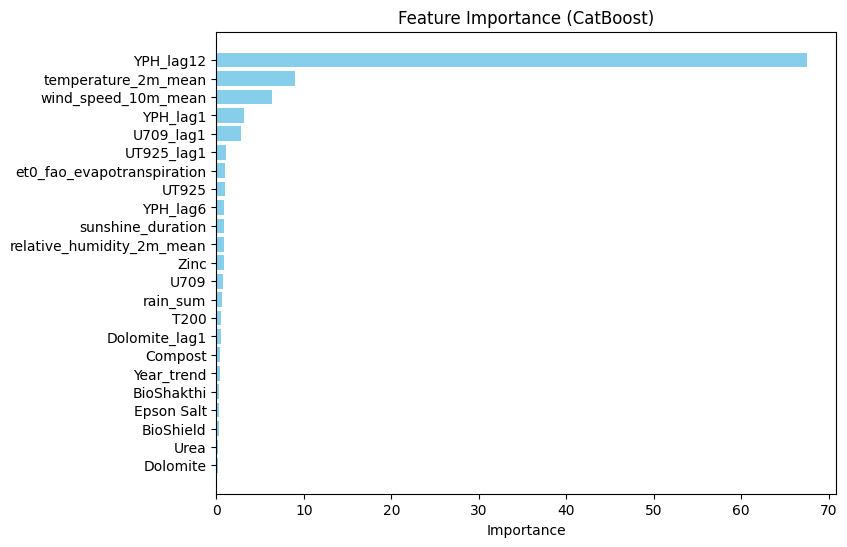

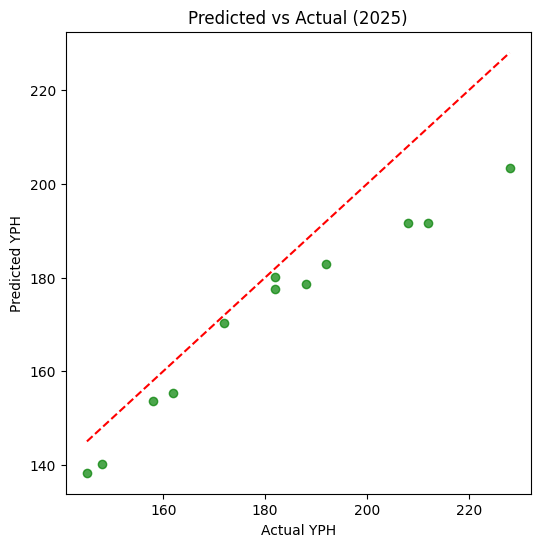

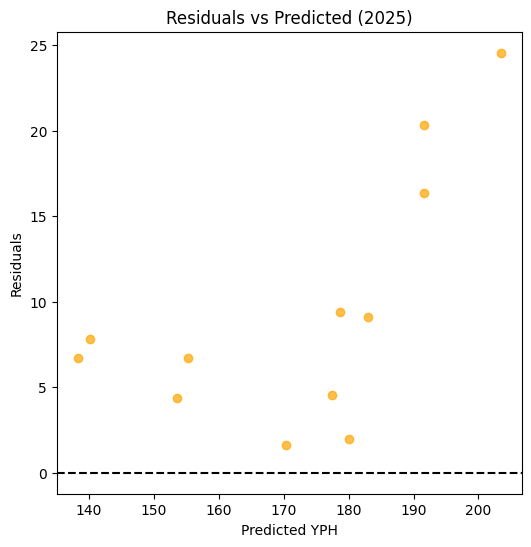

In [30]:
# Results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print Metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAverage Train Metrics")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())

print("\nAverage Test Metrics")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': features,
    'importance': model.get_feature_importance()
}).sort_values(by='importance', ascending=False)

plt.figure(figsize=(8,6))
plt.barh(feature_importance['feature'], feature_importance['importance'], color='skyblue')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance (CatBoost)")
plt.show()

# Predicted vs Actual Plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_test_pred, color='green', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({test_year})")
plt.show()

# Residuals vs Predicted Plot
residuals = y_test - y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(y_test_pred, residuals, color='orange', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({test_year})")
plt.show()